In [3]:
# Load the exact train/test split generated by data_analysis.ipynb
from pathlib import Path
import warnings
import numpy as np
import pandas as pd

# Short training runs (small max_iter) raise ConvergenceWarning; hide them for readability.
warnings.filterwarnings("ignore")

PROJECT_DIR = Path.cwd()
TRAIN_PATH = PROJECT_DIR / "train_data.csv"
TEST_PATH = PROJECT_DIR / "test_data.csv"

train_data = pd.read_csv(TRAIN_PATH)
test_data = pd.read_csv(TEST_PATH)

# The saved files hold the 86 permission columns plus total_permissions (the number of
# permissions an app requests). The Random Forest used all of them (87 features).
#   True  = same 87 inputs as the Random Forest (total_permissions is scaled for the MLP)
#   False = the 86 permission bits only
USE_TOTAL_PERMISSIONS = True

feature_cols = train_data.columns.drop("Result").tolist()
if not USE_TOTAL_PERMISSIONS:
    feature_cols = [col for col in feature_cols if col != "total_permissions"]

X_train = train_data[feature_cols]
y_train = train_data["Result"]
X_test = test_data[feature_cols]
y_test = test_data["Result"]

train_groups = pd.util.hash_pandas_object(X_train, index=False).to_numpy()
test_groups = pd.util.hash_pandas_object(X_test, index=False).to_numpy()
shared_groups = set(train_groups) & set(test_groups)

SEED = 42
print(f"Training samples: {len(X_train):,}")
print(f"Testing samples: {len(X_test):,}")
print(f"Input features: {len(feature_cols)}")
print("Includes total_permissions:", "total_permissions" in feature_cols)
print("Shared permission patterns:", len(shared_groups))


Training samples: 22,096
Testing samples: 7,236
Input features: 87
Includes total_permissions: True
Shared permission patterns: 0


**Train and Test MLP Using the Split from `data_analysis.ipynb`**

Fitting 3 folds for each of 30 candidates, totalling 90 fits

Best Parameters:
{'mlp__activation': 'relu', 'mlp__alpha': np.float64(0.0035753161317240816), 'mlp__batch_size': 128, 'mlp__hidden_layer_sizes': (64,), 'mlp__learning_rate_init': np.float64(0.0007562632622090496), 'mlp__max_iter': 80}

Best Cross-Validation F1 Score: 0.9553829216104321


,params,mean_test_score,std_test_score
23,"{'mlp__activation': 'relu', 'mlp__alpha': 0.00...",0.955383,0.008880
22,"{'mlp__activation': 'relu', 'mlp__alpha': 0.00...",0.953881,0.012696
16,"{'mlp__activation': 'relu', 'mlp__alpha': 0.01...",0.953797,0.009900
3,"{'mlp__activation': 'tanh', 'mlp__alpha': 1.00...",0.953679,0.013089
18,"{'mlp__activation': 'relu', 'mlp__alpha': 0.00...",0.953069,0.007968
24,"{'mlp__activation': 'relu', 'mlp__alpha': 0.03...",0.952272,0.010082
0,"{'mlp__activation': 'relu', 'mlp__alpha': 0.00...",0.951837,0.013753
13,"{'mlp__activation': 'relu', 'mlp__alpha': 0.04...",0.951810,0.006835
9,"{'mlp__activation': 'relu', 'mlp__alpha': 1.42...",0.951687,0.014354
7,"{'mlp__activation': 'relu', 'mlp__alpha': 0.01...",0.950297,0.015007



BEST MLP PERFORMANCE
Parameters: 5,697
Accuracy: 0.9112769485903814
F1 Score: 0.9060304449648712
ROC-AUC: 0.9420108132356597
              precision    recall  f1-score   support

      Benign       0.87      0.96      0.92      3633
   Malicious       0.96      0.86      0.91      3603

    accuracy                           0.91      7236
   macro avg       0.92      0.91      0.91      7236
weighted avg       0.92      0.91      0.91      7236



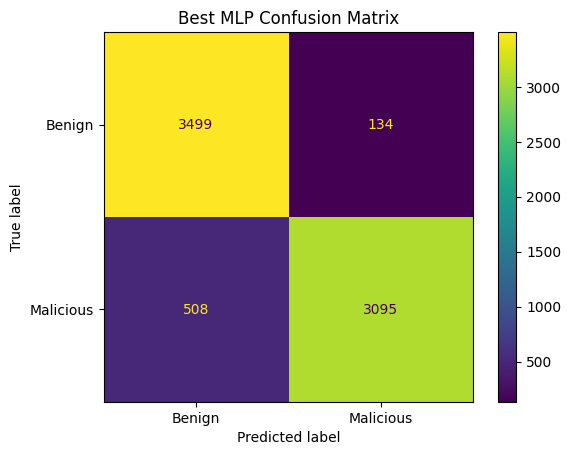

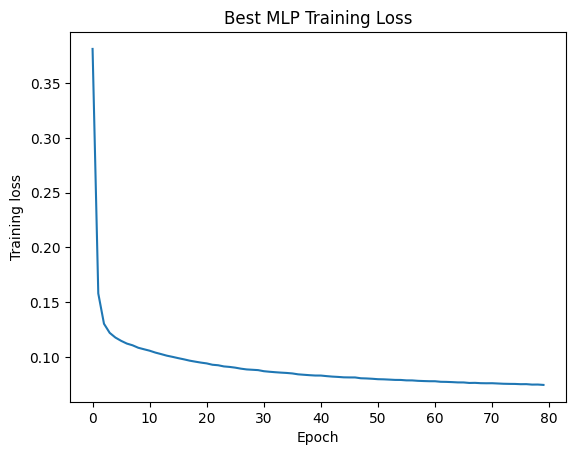

In [4]:
import matplotlib.pyplot as plt
from scipy.stats import loguniform

from sklearn.compose import ColumnTransformer
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score, classification_report,
    ConfusionMatrixDisplay, roc_auc_score
)

# Keep identical permission profiles together during training cross-validation.
groups_train = train_groups

# Different MLP parameters to test (same search style as the Random Forest).
param_grid = {
    "mlp__hidden_layer_sizes": [(32,), (64,), (128,), (256,),
                                (64, 32), (128, 64), (256, 128), (128, 64, 32)],
    "mlp__activation": ["relu", "tanh"],
    "mlp__alpha": loguniform(1e-6, 1e-1),               # L2 penalty
    "mlp__learning_rate_init": loguniform(1e-4, 1e-2),
    "mlp__batch_size": [64, 128, 256, 512],
    "mlp__max_iter": [20, 40, 80],                      # number of epochs
}

def make_mlp_pipeline(columns):
    """Permission bits are already 0/1. Only total_permissions (1 to 65) is scaled.
    The scaler sits inside the pipeline, so each CV fold fits it on its own training part."""
    steps = []
    if "total_permissions" in columns:
        scale_count = ColumnTransformer(
            [("count", StandardScaler(), ["total_permissions"])],
            remainder="passthrough"
        )
        steps.append(("scale", scale_count))
    # early_stopping=False on purpose: scikit-learn's built-in validation split picks random
    # rows, so identical permission patterns would land in both training and validation.
    steps.append(("mlp", MLPClassifier(solver="adam", early_stopping=False,
                                       random_state=SEED)))
    return Pipeline(steps)

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)

search = RandomizedSearchCV(
    estimator=make_mlp_pipeline(feature_cols),
    param_distributions=param_grid,
    n_iter=30,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    random_state=SEED,
    verbose=1,
    refit=True
)

# Tune on training data only; the fixed test split remains held out.
search.fit(X_train, y_train, groups=groups_train)
best_mlp = search.best_estimator_

print("\nBest Parameters:")
print(search.best_params_)
print("\nBest Cross-Validation F1 Score:", search.best_score_)

results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(results[["params", "mean_test_score", "std_test_score"]].head(10))

y_pred = best_mlp.predict(X_test)
y_prob = best_mlp.predict_proba(X_test)[:, 1]

mlp_model = best_mlp.named_steps["mlp"]
n_params = sum(w.size for w in mlp_model.coefs_) + sum(b.size for b in mlp_model.intercepts_)

print("\nBEST MLP PERFORMANCE")
print("Parameters:", f"{n_params:,}")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print(classification_report(y_test, y_pred, target_names=["Benign", "Malicious"]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Benign", "Malicious"])
plt.title("Best MLP Confusion Matrix")
plt.show()

# Training loss per epoch of the final model (it should fall and then level off).
plt.plot(mlp_model.loss_curve_)
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Best MLP Training Loss")
plt.show()

full_set_results = {
    "Model": "MLP, full feature set", "Features": len(feature_cols), "Parameters": n_params,
    "CV F1": search.best_score_, "Test Accuracy": accuracy_score(y_test, y_pred),
    "Test F1": f1_score(y_test, y_pred), "Test Recall": recall_score(y_test, y_pred),
    "Test ROC-AUC": roc_auc_score(y_test, y_prob),
}


Using these 20 SHAP-ranked features:
                                                   Feature  Mean_SHAP_Value
                       android.permission.READ_PHONE_STATE         0.170364
                com.google.android.c2dm.permission.RECEIVE         0.076599
                 android.permission.RECEIVE_BOOT_COMPLETED         0.056213
          com.android.launcher.permission.INSTALL_SHORTCUT         0.056205
                 android.permission.ACCESS_COARSE_LOCATION         0.041662
                   android.permission.ACCESS_FINE_LOCATION         0.035519
                  android.permission.READ_EXTERNAL_STORAGE         0.029911
                                         total_permissions         0.028810
                    android.permission.SYSTEM_ALERT_WINDOW         0.025584
                              android.permission.GET_TASKS         0.025440
                               com.android.vending.BILLING         0.017535
                              android.permission.WA

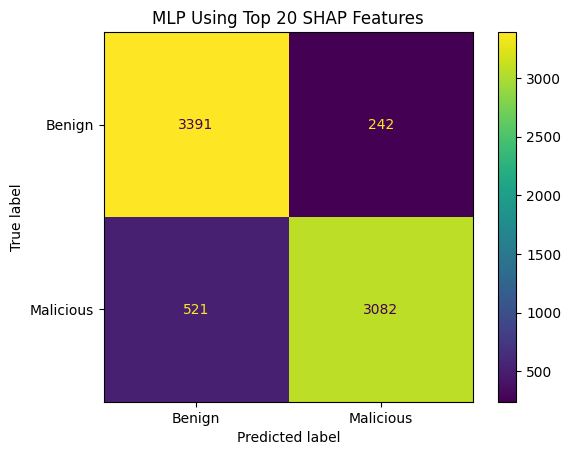

In [5]:
# Load the top 20 features exported by SHAP_rankings.ipynb.
SHAP_FEATURES_PATH = PROJECT_DIR / "top_20_shap_features.csv"
shap_feature_ranking = pd.read_csv(SHAP_FEATURES_PATH)

top_20_features = shap_feature_ranking["Feature"].tolist()
if not USE_TOTAL_PERMISSIONS:
    # The SHAP list was built on the 87-feature data and contains total_permissions.
    top_20_features = [col for col in top_20_features if col != "total_permissions"]
print(f"Using these {len(top_20_features)} SHAP-ranked features:")
print(shap_feature_ranking[shap_feature_ranking["Feature"].isin(top_20_features)].to_string(index=False))

# Tune with the same cross-validation strategy and evaluate on the same held-out split.
top_20_search = RandomizedSearchCV(
    estimator=make_mlp_pipeline(top_20_features),
    param_distributions=param_grid,
    n_iter=30,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    random_state=SEED,
    verbose=1,
    refit=True
)

top_20_search.fit(X_train[top_20_features], y_train, groups=groups_train)
top_20_mlp = top_20_search.best_estimator_

y_pred_top_20 = top_20_mlp.predict(X_test[top_20_features])
y_prob_top_20 = top_20_mlp.predict_proba(X_test[top_20_features])[:, 1]

top_20_model = top_20_mlp.named_steps["mlp"]
n_params_top_20 = (sum(w.size for w in top_20_model.coefs_)
                   + sum(b.size for b in top_20_model.intercepts_))

print("\nTOP-20 SHAP FEATURE MLP PERFORMANCE")
print("Features used:", len(top_20_features))
print("Parameters:", f"{n_params_top_20:,}")
print("Best Parameters:", top_20_search.best_params_)
print("Best Cross-Validation F1 Score:", top_20_search.best_score_)
print("Accuracy:", accuracy_score(y_test, y_pred_top_20))
print("F1 Score:", f1_score(y_test, y_pred_top_20))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_top_20))
print(classification_report(y_test, y_pred_top_20, target_names=["Benign", "Malicious"]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_top_20, display_labels=["Benign", "Malicious"])
plt.title("MLP Using Top 20 SHAP Features")
plt.show()

top_20_results = {
    "Model": "MLP, top-20 features", "Features": len(top_20_features), "Parameters": n_params_top_20,
    "CV F1": top_20_search.best_score_, "Test Accuracy": accuracy_score(y_test, y_pred_top_20),
    "Test F1": f1_score(y_test, y_pred_top_20), "Test Recall": recall_score(y_test, y_pred_top_20),
    "Test ROC-AUC": roc_auc_score(y_test, y_prob_top_20),
}


In [6]:
# Side-by-side summary of the two MLP runs, ready to compare with the Random Forest outputs.
summary = pd.DataFrame([full_set_results, top_20_results]).set_index("Model")
display(summary.round(4))
summary.round(4).to_csv(PROJECT_DIR / "mlp_results.csv")
print("Saved mlp_results.csv")


,Features,Parameters,CV F1,Test Accuracy,Test F1,Test Recall,Test ROC-AUC
Model,,,,,,,
"MLP, full feature set",87,5697,0.9554,0.9113,0.9060,0.8590,0.9420
"MLP, top-20 features",20,5633,0.9572,0.8946,0.8899,0.8554,0.9392


Saved mlp_results.csv
